# Why the model flags a transaction

SHAP explanations for the tuned LightGBM (seed 42, the model checked on test): which columns drive its scores overall, and why a single transaction gets a high or a low score. Explanations are computed on 5,000 random transactions from valid; they describe the model and change nothing in it.

In [1]:
import lightgbm as lgb
from fraud.data import load_train
from fraud.features import add_features
from fraud.models import make_lightgbm
from fraud.split import time_split

In [2]:
df = add_features(load_train())
train, valid, _ = time_split(df)

NON_FEATURES = ["isFraud", "TransactionDT", "TransactionID"]
X_train, y_train = train.drop(columns=NON_FEATURES), train["isFraud"]
X_valid, y_valid = valid.drop(columns=NON_FEATURES), valid["isFraud"]

lgbm = make_lightgbm(seed=42, n_jobs=8)
lgbm.fit(X_train, y_train, eval_X=X_valid, eval_y=y_valid, callbacks=[lgb.early_stopping(100, verbose=False)])
print(f"trees: {lgbm.best_iteration_}")

trees: 473


In [3]:
sample = X_valid.sample(5000, random_state=42)
contrib = lgbm.predict(sample, pred_contrib=True)
raw = lgbm.predict(sample, raw_score=True)
print(contrib.shape)
print(f"largest gap between the sum of contributions and the raw score: {abs(contrib.sum(axis=1) - raw).max():.6f}")

(5000, 441)
largest gap between the sum of contributions and the raw score: 0.000000


In [4]:
import pandas as pd

i = raw.argmax()
receipt = pd.Series(contrib[i, :-1], index=sample.columns)
print(f"starting point (average transaction): {contrib[i, -1]:.2f}")
print(receipt.sort_values(key=abs, ascending=False).head(5).round(2))
print(f"all 440 contributions together: {receipt.sum():.2f}")
print(f"starting point + contributions = raw score: {contrib[i, -1] + receipt.sum():.2f} = {raw[i]:.2f}")

starting point (average transaction): -6.46
C1            1.45
V258          1.45
V45           0.87
DeviceInfo    0.84
C11           0.73
dtype: float64
all 440 contributions together: 15.14
starting point + contributions = raw score: 8.68 = 8.68


For the most suspicious transaction in the sample the model starts from -6.46 (an ordinary transaction) and ends at 8.68. The five largest contributions come from `C1`, `V258`, `V45`, `DeviceInfo` and `C11` (+0.7 to +1.5 each), but together they add only 5.3 of the 15.1: the rest comes from many small pushes by other columns.

In [5]:
importance = pd.Series(abs(contrib[:, :-1]).mean(axis=0), index=sample.columns).sort_values(ascending=False)
print(importance.head(20).round(3))

OUR_FEATURES = [c for c in sample.columns if c.endswith("_start_day")]
rank = importance.rank(ascending=False).astype(int)
print(pd.DataFrame({"importance": importance[OUR_FEATURES].round(3), "rank of 440": rank[OUR_FEATURES]}))

C13               0.328
TransactionAmt    0.270
card_start_day    0.185
P_emaildomain     0.172
card6             0.168
C5                0.158
card2             0.155
V70               0.153
card1             0.145
D4_start_day      0.140
C14               0.139
C1                0.132
card5             0.113
addr1             0.107
D15_start_day     0.106
D11_start_day     0.098
D2_start_day      0.087
D10_start_day     0.082
C11               0.081
C2                0.079
dtype: float64
                importance  rank of 440
card_start_day       0.185            3
D2_start_day         0.087           17
D4_start_day         0.140           10
D6_start_day         0.012           92
D10_start_day        0.082           18
D11_start_day        0.098           16
D12_start_day        0.027           53
D14_start_day        0.022           60
D15_start_day        0.106           15


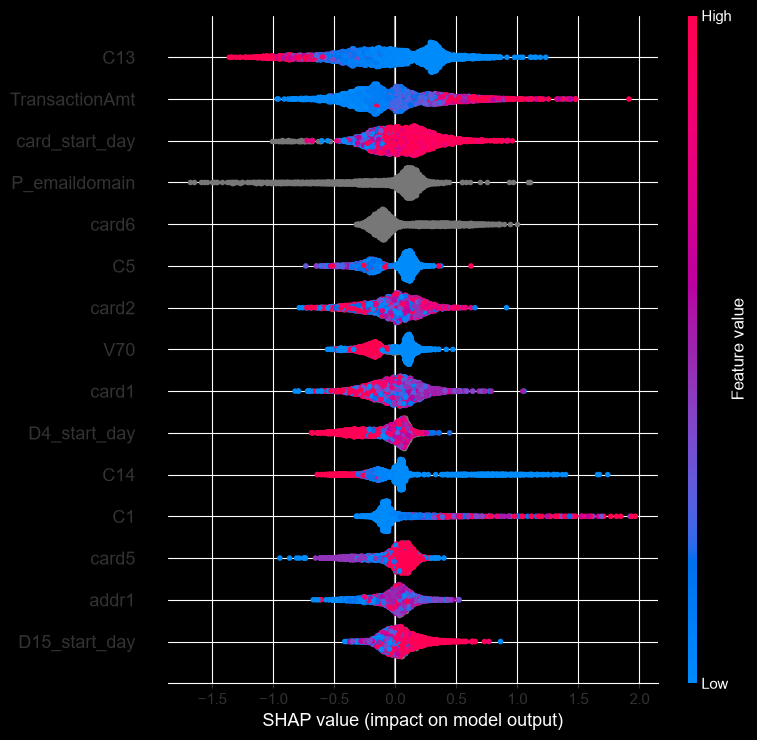

In [6]:
import shap

shap.summary_plot(contrib[:, :-1], sample, max_display=15)

Large amounts push towards fraud and small ones towards honest. High `C13` pushes towards honest, while `C1` and `C14` are usually near zero but now and then push strongly towards fraud. A late `card_start_day` or `D15_start_day` (a recently seen card) pushes towards fraud more often. `card1`, `card2`, `card5` and `addr1` are codes, not quantities, so their colours are mixed; text columns such as `P_emaildomain` and `card6` are grey and push both ways depending on the value.

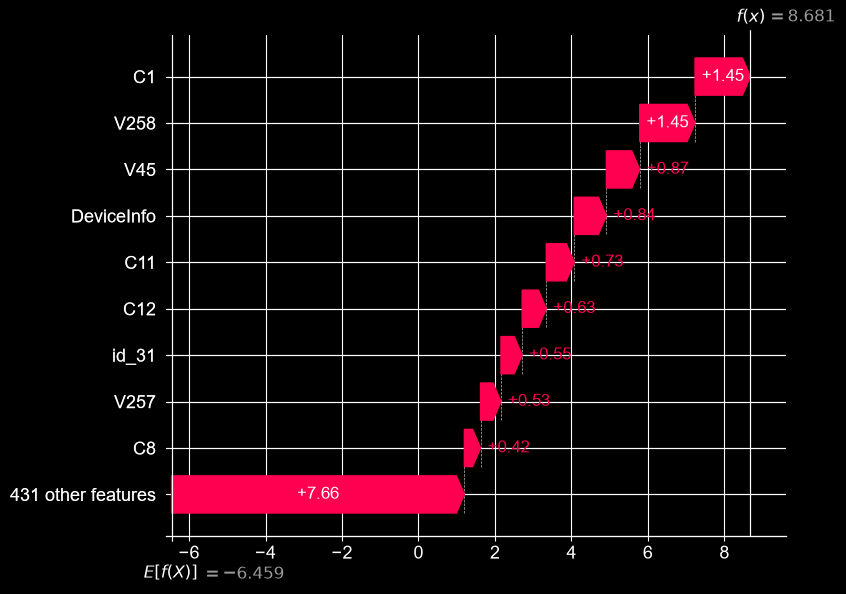

In [7]:
explanation = shap.Explanation(values=contrib[:, :-1], base_values=contrib[:, -1], feature_names=list(sample.columns))
shap.plots.waterfall(explanation[i], max_display=10)

The waterfall shows the same receipt as a picture: from -6.46 to 8.68, with `C1` and `V258` (+1.45 each) on top. All nine largest reasons push towards fraud, and the other 431 columns add 7.66, about half of the climb. As reason codes they explain the decision only in part: the device (`DeviceInfo`) and browser (`id_31`) are clear, while the `C` and `V` columns are masked by Vesta and have no plain meaning.